<a href="https://colab.research.google.com/github/Jarinnnnnn/Tomato_CVPR_Assignment/blob/main/Tomato_CVPR_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [9]:
from pathlib import Path

archive = Path('/content/drive/MyDrive/Tomato cvpr/Dataset.rar')

print("Dataset Found:", archive.exists())

Dataset Found: True


In [10]:
!apt-get install -y unrar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [11]:
!unrar x -o+ "{archive}" /content/



UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from /content/drive/MyDrive/Tomato cvpr/Dataset.rar

Creating    /content/Dataset                                          OK
Creating    /content/Dataset/Three Classes                            OK
Creating    /content/Dataset/Three Classes/Reject                     OK
Extracting  /content/Dataset/Three Classes/Reject/reject (1).jpg           0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (10).jpg          0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (100).jpg         0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (101).jpg         0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (102).jpg         0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (103).jpg         0%  OK 
Extracting  /content/Dataset/Three Classes/Reject/reject (104).jpg         0%  OK 
Extr

In [12]:
!ls "/content/Dataset"


'Three Classes'  'Two Classes'


In [13]:
!ls "/content/Dataset/Three Classes"

Reject	Ripe  Unripe


In [1]:
import os
import time
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [5]:
from google.colab import drive
from pathlib import Path
from torchvision import datasets
import subprocess

drive.mount('/content/drive')

archive = Path('/content/drive/MyDrive/Tomato cvpr/Dataset.rar')

assert archive.is_file(), "Dataset.rar not found"

print("Dataset Found:", archive.exists())

!apt-get install -y unrar

subprocess.run(
    ["unrar", "x", "-o+", str(archive), "/content/"],
    check=True
)

DATASET_PATH = "/content/Dataset/Three Classes"

dataset = datasets.ImageFolder(DATASET_PATH)

class_names = dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of Classes:", num_classes)
print("Total Images:", len(dataset))


Mounted at /content/drive
Dataset Found: True
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Classes: ['Reject', 'Ripe', 'Unripe']
Number of Classes: 3
Total Images: 2400


Reject : 800
Ripe : 800
Unripe : 800


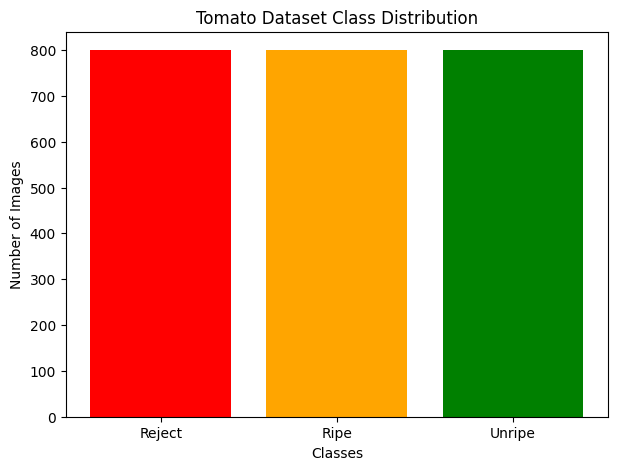

In [6]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(dataset.targets)

for i, name in enumerate(class_names):
    print(name, ":", counts[i])

plt.figure(figsize=(7, 5))

plt.bar(
    class_names,
    [counts[i] for i in range(num_classes)],
    color=['red', 'orange', 'green']
)

plt.title("Tomato Dataset Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.show()

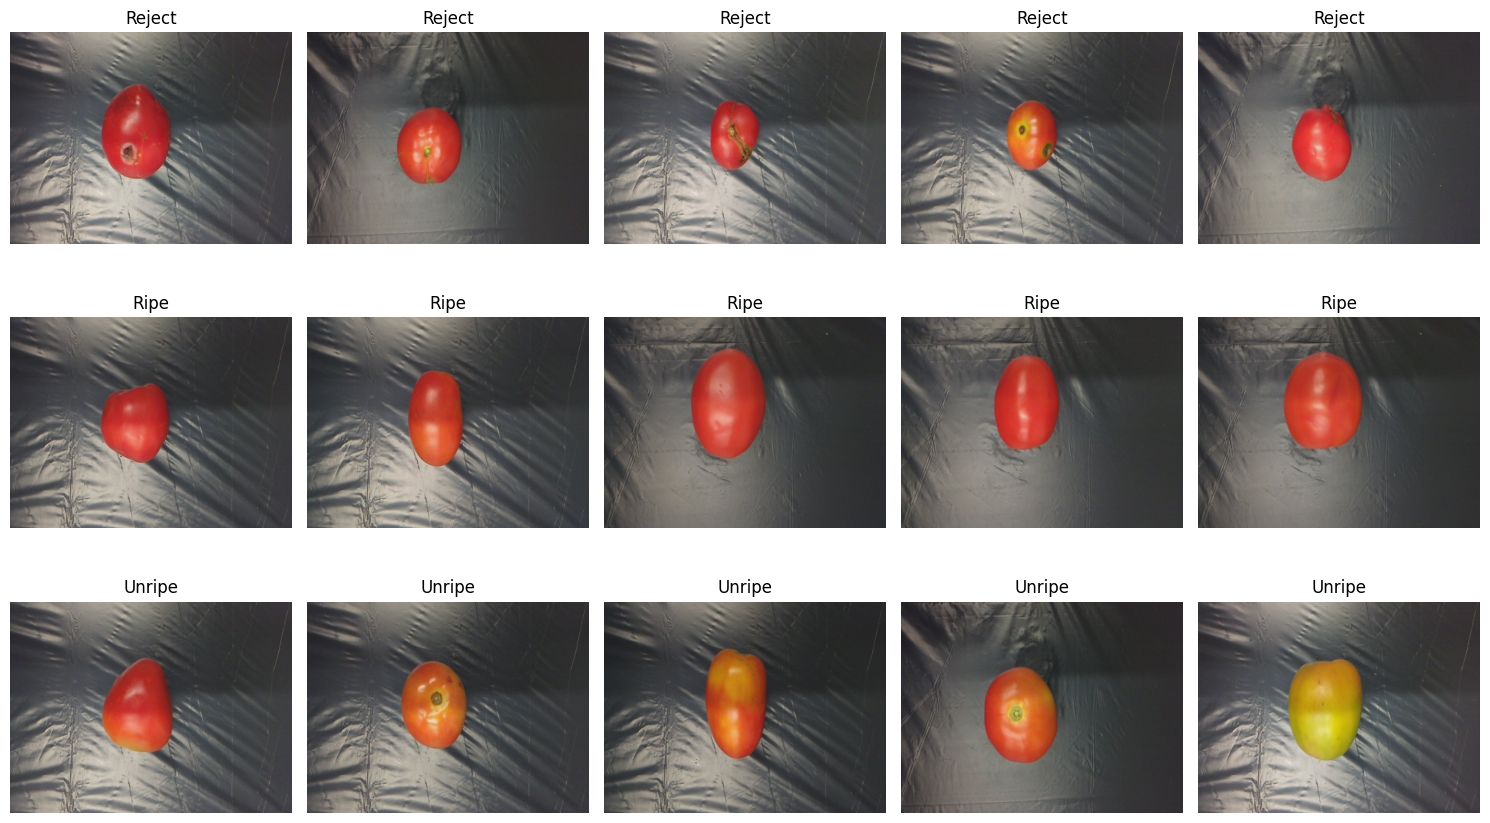

In [8]:
import random

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, name in enumerate(class_names):

    indices = [
        j for j, label in enumerate(dataset.targets)
        if label == i
    ]

    selected = random.sample(indices, 5)

    for j, idx in enumerate(selected):

        image, label = dataset[idx]

        axes[i, j].imshow(image)
        axes[i, j].set_title(name)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


Class: Reject
Image Size: (640, 480)
Image Shape: (480, 640, 3)
Minimum Pixel: 24
Maximum Pixel: 255


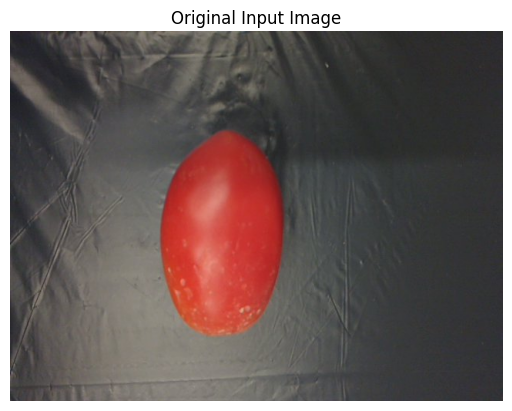

In [9]:
import numpy as np

image, label = dataset[0]
img = np.array(image)

print("Class:", class_names[label])
print("Image Size:", image.size)
print("Image Shape:", img.shape)
print("Minimum Pixel:", img.min())
print("Maximum Pixel:", img.max())

plt.imshow(image)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

In [3]:
from google.colab import drive
from pathlib import Path
from torchvision import datasets
import subprocess

drive.mount('/content/drive')

archive = Path('/content/drive/MyDrive/Tomato cvpr/Dataset.rar')

assert archive.is_file(), "Dataset not found"

!apt-get install -y unrar

subprocess.run(
    ["unrar", "x", "-o+", str(archive), "/content/"],
    check=True
)

DATASET_PATH = "/content/Dataset/Three Classes"

dataset = datasets.ImageFolder(DATASET_PATH)

class_names = dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of Classes:", num_classes)
print("Total Images:", len(dataset))

Mounted at /content/drive
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
Classes: ['Reject', 'Ripe', 'Unripe']
Number of Classes: 3
Total Images: 2400


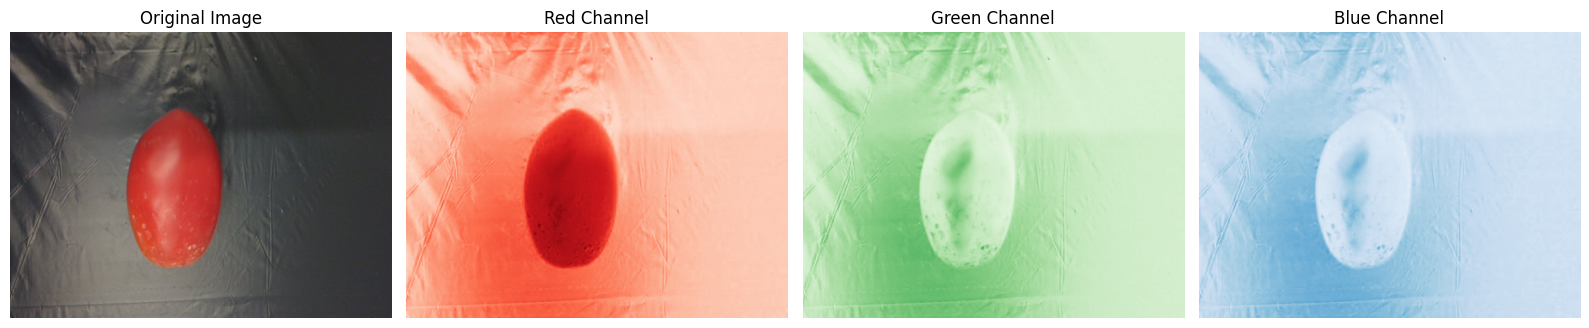

In [4]:
import numpy as np
import matplotlib.pyplot as plt

image, label = dataset[0]
img = np.array(image.convert("RGB"))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(img)
ax[0].set_title("Original Image")

ax[1].imshow(img[:, :, 0], cmap="Reds", vmin=0, vmax=255)
ax[1].set_title("Red Channel")

ax[2].imshow(img[:, :, 1], cmap="Greens", vmin=0, vmax=255)
ax[2].set_title("Green Channel")

ax[3].imshow(img[:, :, 2], cmap="Blues", vmin=0, vmax=255)
ax[3].set_title("Blue Channel")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


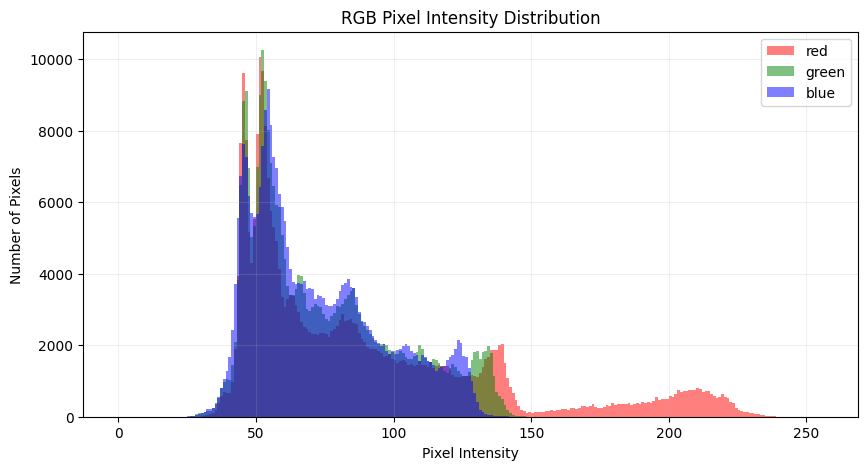

In [5]:
plt.figure(figsize=(10, 5))

for i, color in enumerate(['red', 'green', 'blue']):

    plt.hist(
        img[:, :, i].ravel(),
        bins=256,
        range=(0, 256),
        color=color,
        alpha=0.5,
        label=color
    )

plt.title("RGB Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


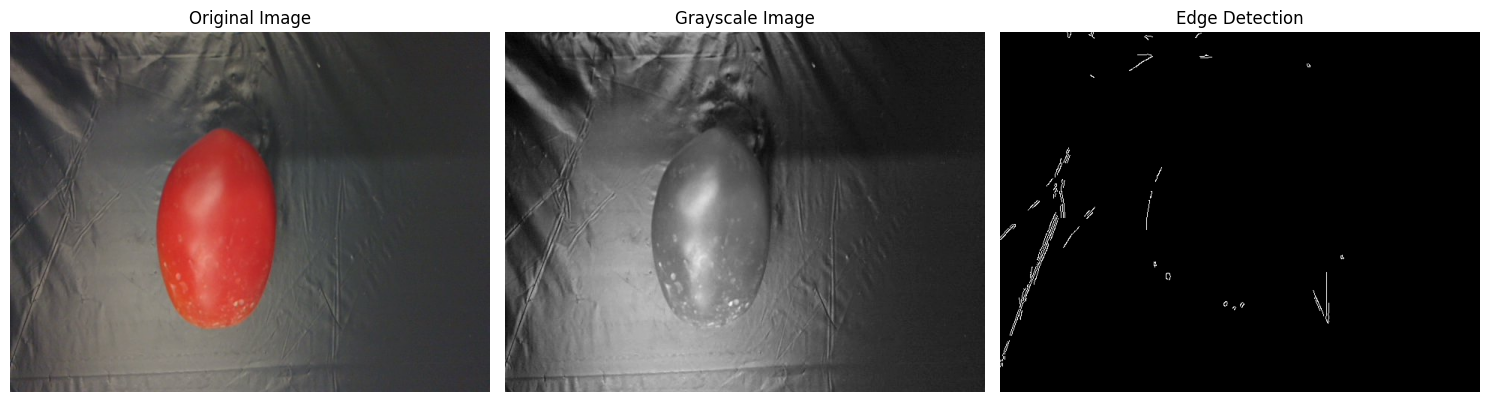

In [6]:
import cv2

gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

edge = cv2.Canny(gray, 100, 200)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(img)
ax[0].set_title("Original Image")

ax[1].imshow(gray, cmap="gray")
ax[1].set_title("Grayscale Image")

ax[2].imshow(edge, cmap="gray")
ax[2].set_title("Edge Detection")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [8]:
IMG_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Transformation Ready")

Image Size: 128
Batch Size: 32
Transformation Ready


In [9]:
DATASET_PATH = "/content/Dataset/Three Classes"

dataset = datasets.ImageFolder(DATASET_PATH)

indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=42
)

train_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=train_transform
    ),
    train_idx
)

val_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=test_transform
    ),
    val_idx
)

test_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=test_transform
    ),
    test_idx
)

class_names = dataset.classes
num_classes = len(class_names)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))


Training Images: 1680
Validation Images: 360
Testing Images: 360


In [10]:
DATASET_PATH = "/content/Dataset/Three Classes"

dataset = datasets.ImageFolder(DATASET_PATH)

indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=42
)

train_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=train_transform
    ),
    train_idx
)

val_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=test_transform
    ),
    val_idx
)

test_dataset = Subset(
    datasets.ImageFolder(
        DATASET_PATH,
        transform=test_transform
    ),
    test_idx
)

class_names = dataset.classes
num_classes = len(class_names)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))


Training Images: 1680
Validation Images: 360
Testing Images: 360


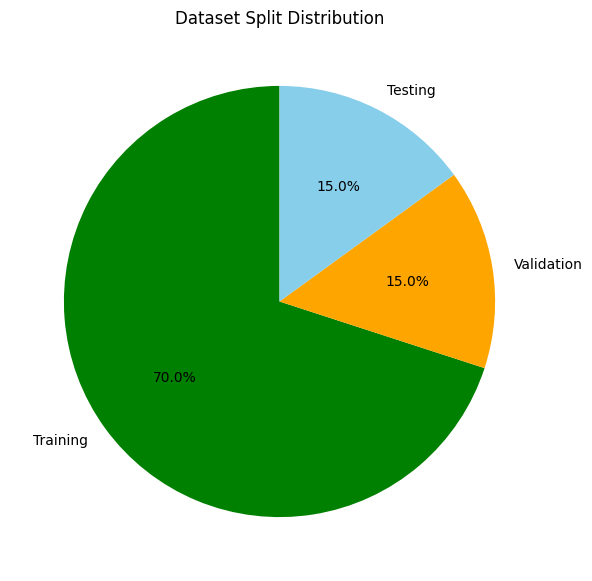

In [11]:
sizes = [
    len(train_dataset),
    len(val_dataset),
    len(test_dataset)
]

plt.figure(figsize=(7, 7))

plt.pie(
    sizes,
    labels=['Training', 'Validation', 'Testing'],
    autopct='%1.1f%%',
    colors=['green', 'orange', 'skyblue'],
    startangle=90
)

plt.title("Dataset Split Distribution")
plt.show()

In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

images, labels_batch = next(iter(train_loader))

print("Input Batch Shape:", images.shape)
print("Label Batch Shape:", labels_batch.shape)

Input Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])


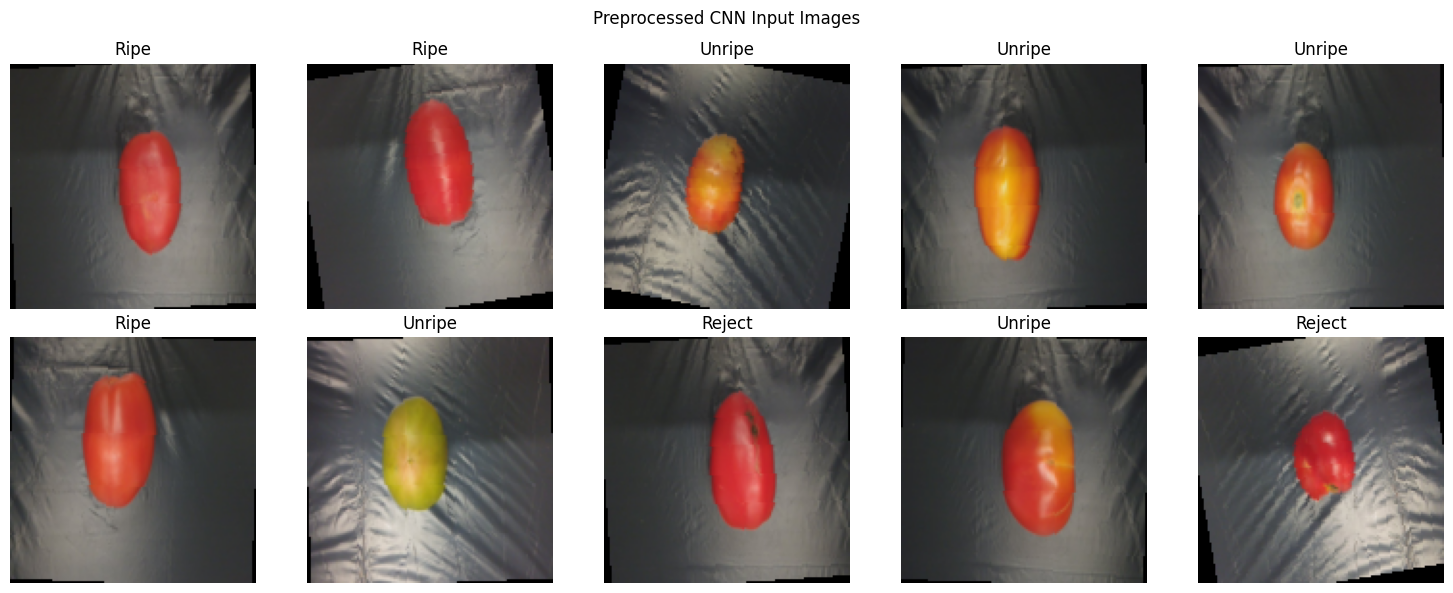

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    img_tensor = images[i].permute(1, 2, 0).numpy()

    ax.imshow(img_tensor)
    ax.set_title(class_names[labels_batch[i].item()])
    ax.axis("off")

plt.suptitle("Preprocessed CNN Input Images")
plt.tight_layout()
plt.show()



In [14]:
class BasicCNN(nn.Module):

    def __init__(self, num_classes=3):
        super(BasicCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = BasicCNN(num_classes).to(device)

print(model)

print("Total Parameters:",
      sum(p.numel() for p in model.parameters()))


BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)
Total Parameters: 2121251


In [15]:
model.eval()

x = images[:1].to(device)

print("Input Shape:", x.shape)

with torch.no_grad():

    for i, layer in enumerate(model.features):
        x = layer(x)

        print(
            f"Layer {i+1}:",
            layer.__class__.__name__,
            x.shape
        )

    for i, layer in enumerate(model.classifier):
        x = layer(x)

        print(
            layer.__class__.__name__,
            x.shape
        )


Input Shape: torch.Size([1, 3, 128, 128])
Layer 1: Conv2d torch.Size([1, 16, 128, 128])
Layer 2: ReLU torch.Size([1, 16, 128, 128])
Layer 3: MaxPool2d torch.Size([1, 16, 64, 64])
Layer 4: Conv2d torch.Size([1, 32, 64, 64])
Layer 5: ReLU torch.Size([1, 32, 64, 64])
Layer 6: MaxPool2d torch.Size([1, 32, 32, 32])
Layer 7: Conv2d torch.Size([1, 64, 32, 32])
Layer 8: ReLU torch.Size([1, 64, 32, 32])
Layer 9: MaxPool2d torch.Size([1, 64, 16, 16])
Flatten torch.Size([1, 16384])
Linear torch.Size([1, 128])
ReLU torch.Size([1, 128])
Dropout torch.Size([1, 128])
Linear torch.Size([1, 3])


In [16]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Epochs:", EPOCHS)

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001
Epochs: 5


In [17]:
import copy

train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_loss = float("inf")
best_model = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for inputs, targets in train_loader:

        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    model.eval()

    running_val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, targets in val_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_val_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

    val_loss = running_val_loss / val_total
    val_acc = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

model.load_state_dict(best_model)

print("Training Completed Successfully!")


Epoch [1/5] | Train Loss: 0.9515 | Train Acc: 52.62% | Val Loss: 0.5955 | Val Acc: 74.44%
Epoch [2/5] | Train Loss: 0.5944 | Train Acc: 72.80% | Val Loss: 0.5277 | Val Acc: 76.67%
Epoch [3/5] | Train Loss: 0.5083 | Train Acc: 76.07% | Val Loss: 0.4983 | Val Acc: 74.72%
Epoch [4/5] | Train Loss: 0.4792 | Train Acc: 76.13% | Val Loss: 0.4826 | Val Acc: 78.06%
Epoch [5/5] | Train Loss: 0.4489 | Train Acc: 78.87% | Val Loss: 0.4826 | Val Acc: 78.33%
Training Completed Successfully!


In [18]:
SAVE_PATH = "/content/drive/MyDrive/Tomato cvpr/BasicCNN.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMG_SIZE,
    "train_losses": train_losses,
    "val_losses": val_losses,
    "train_accs": train_accs,
    "val_accs": val_accs
}, SAVE_PATH)

print("Model Saved Successfully!")

Model Saved Successfully!


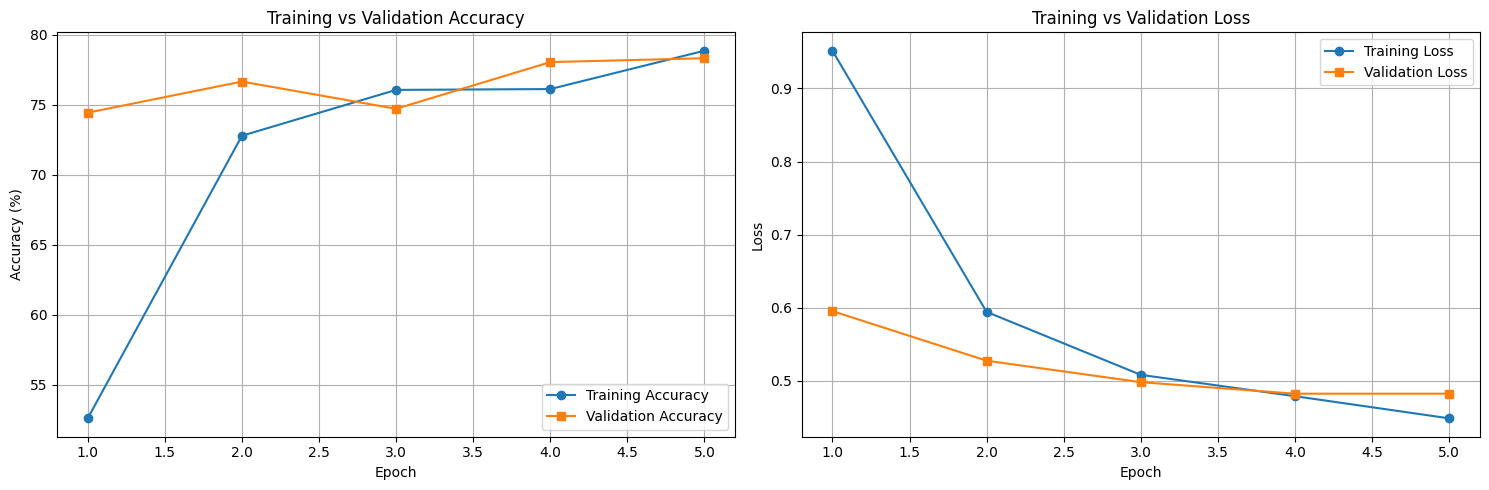

In [19]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_accs) + 1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(epochs, train_accs, 'o-',
           label="Training Accuracy")

ax[0].plot(epochs, val_accs, 's-',
           label="Validation Accuracy")

ax[0].set_title("Training vs Validation Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy (%)")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(epochs, train_losses, 'o-',
           label="Training Loss")

ax[1].plot(epochs, val_losses, 's-',
           label="Validation Loss")

ax[1].set_title("Training vs Validation Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()


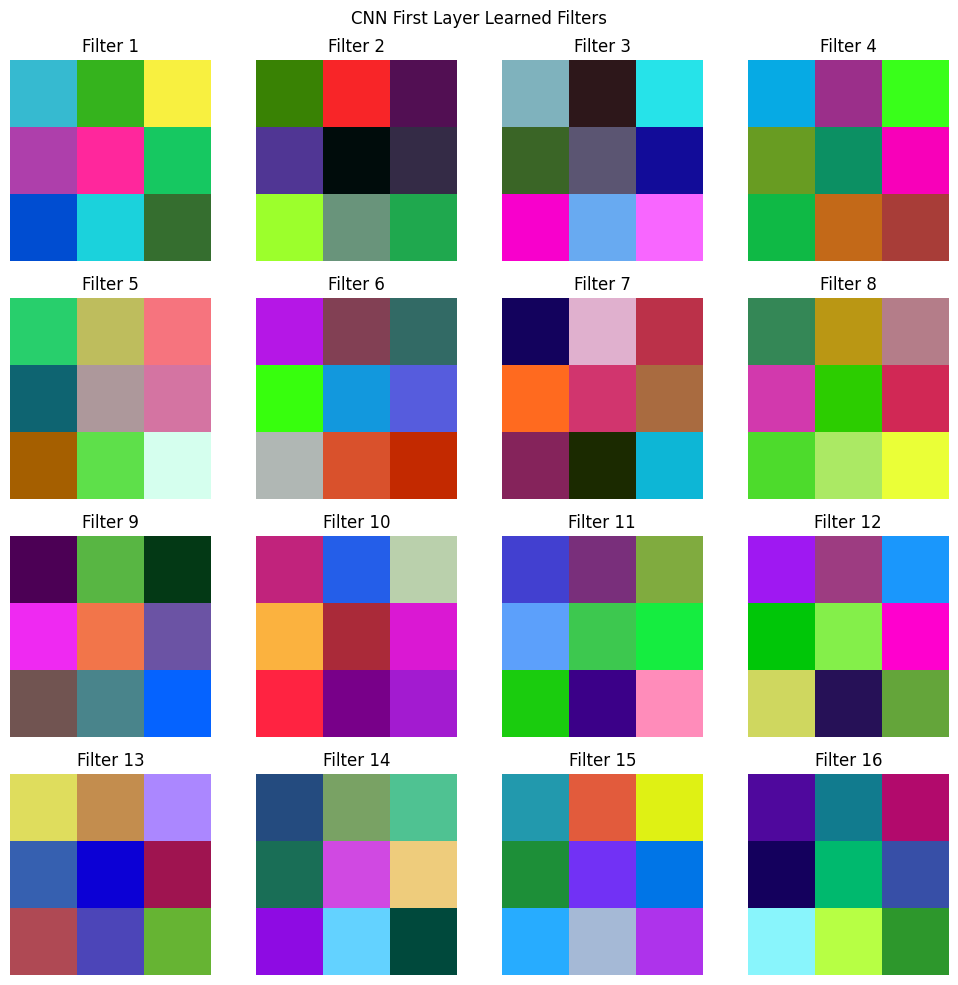

Filter Shape: torch.Size([16, 3, 3, 3])


In [20]:
filters = model.features[0].weight.detach().cpu()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    f = filters[i].permute(1, 2, 0)

    f = (f - f.min()) / (f.max() - f.min() + 1e-8)

    ax.imshow(f.numpy(), interpolation="nearest")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")

plt.suptitle("CNN First Layer Learned Filters")
plt.tight_layout()
plt.show()

print("Filter Shape:", filters.shape)


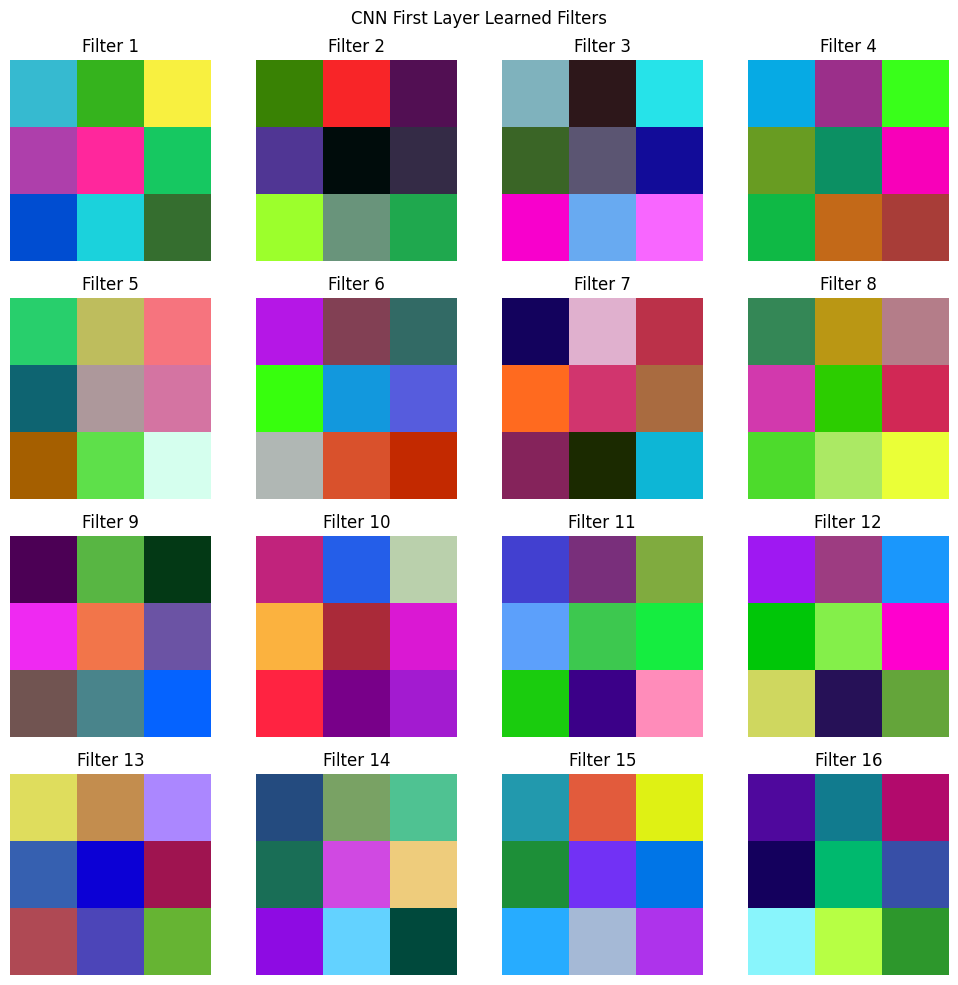

Filter Shape: torch.Size([16, 3, 3, 3])


In [21]:
filters = model.features[0].weight.detach().cpu()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    f = filters[i].permute(1, 2, 0)

    f = (f - f.min()) / (f.max() - f.min() + 1e-8)

    ax.imshow(f.numpy(), interpolation="nearest")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")

plt.suptitle("CNN First Layer Learned Filters")
plt.tight_layout()
plt.show()

print("Filter Shape:", filters.shape)



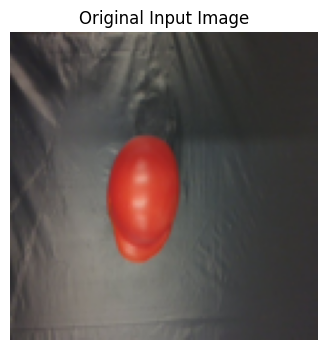

Layer: 1
Feature Shape: torch.Size([16, 128, 128])


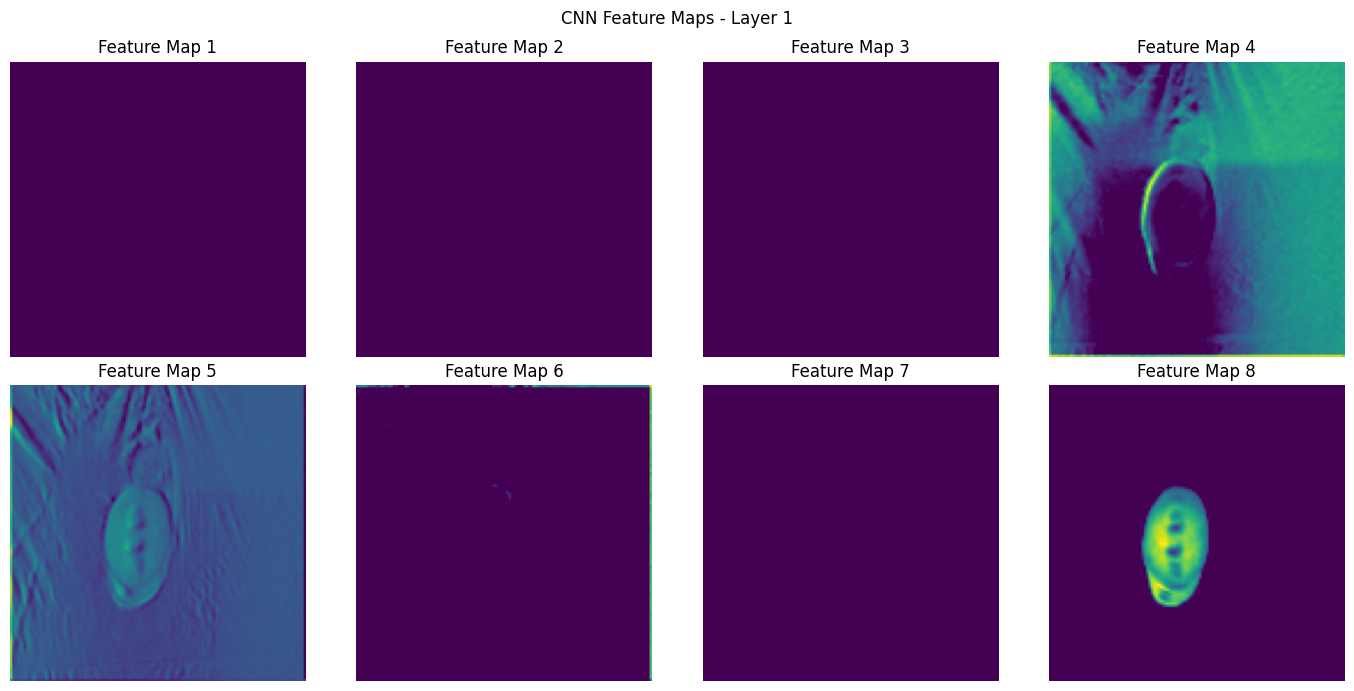

Layer: 4
Feature Shape: torch.Size([32, 64, 64])


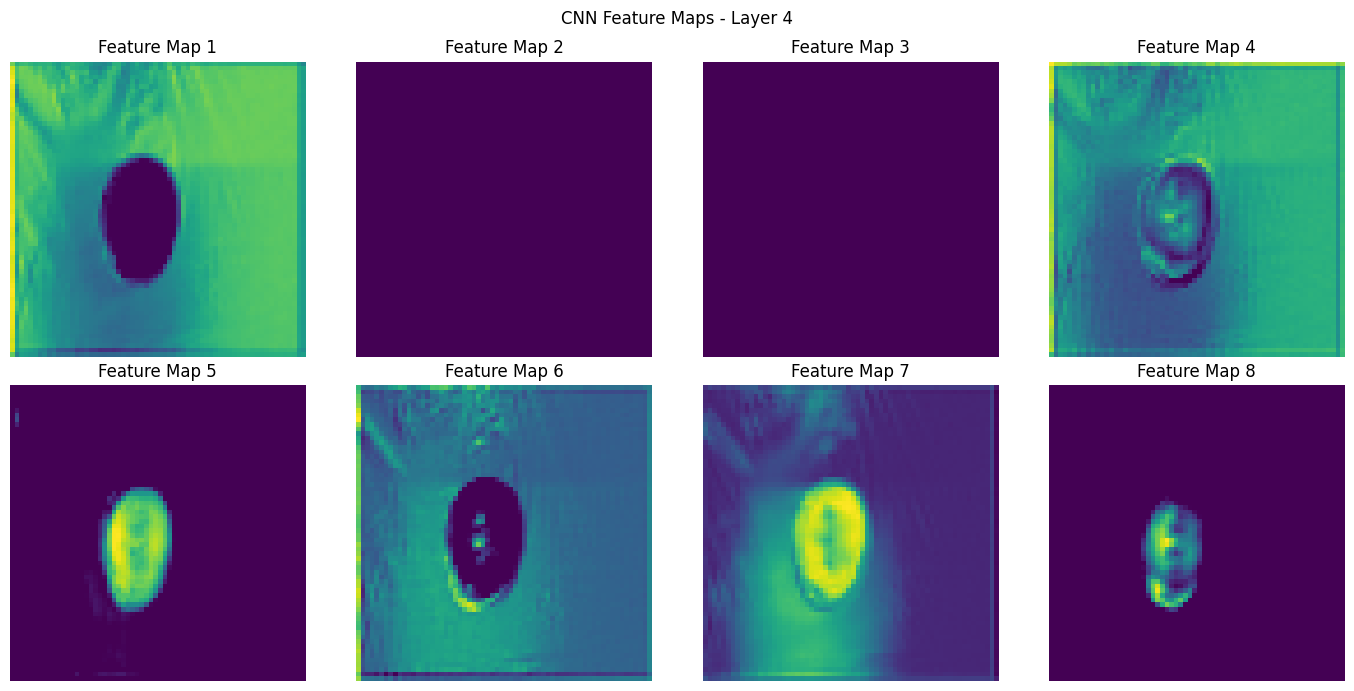

Layer: 7
Feature Shape: torch.Size([64, 32, 32])


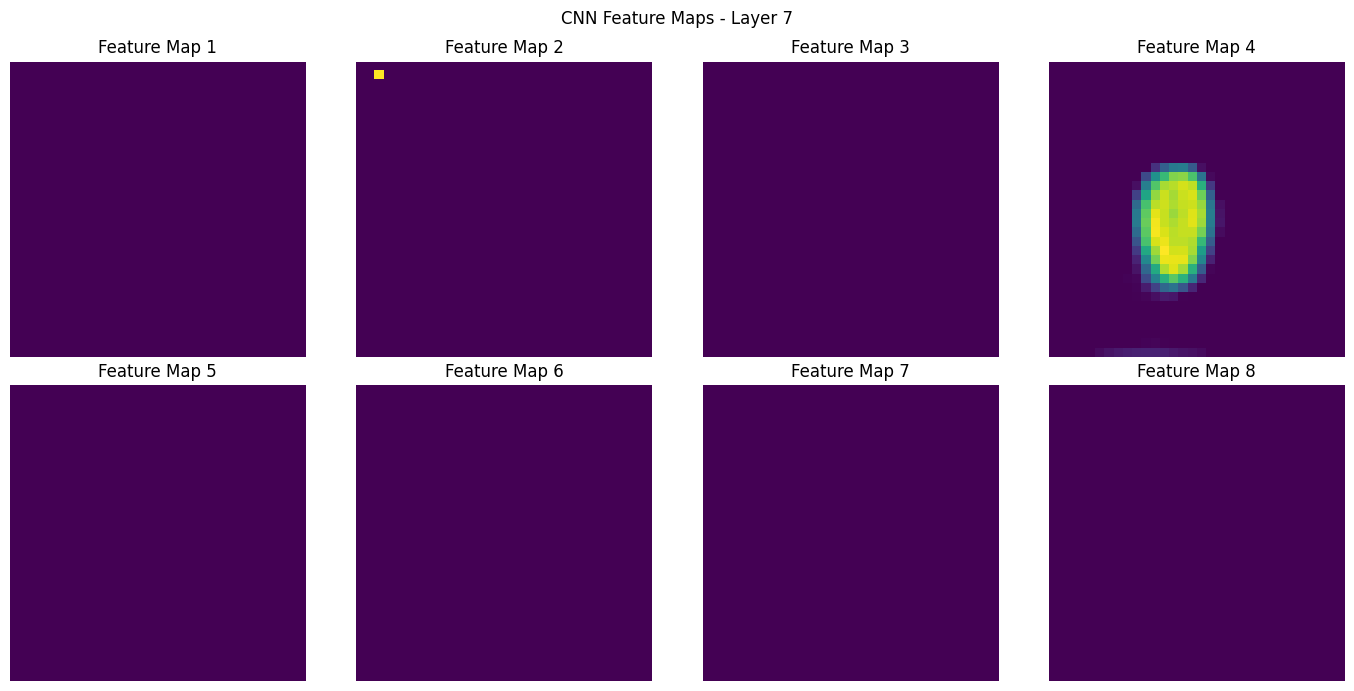

In [22]:
model.eval()

images, labels = next(iter(test_loader))

x = images[0:1].to(device)

plt.figure(figsize=(4, 4))
plt.imshow(images[0].permute(1, 2, 0).cpu().numpy())
plt.title("Original Input Image")
plt.axis("off")
plt.show()

with torch.no_grad():

    for i, layer in enumerate(model.features):

        x = layer(x)

        if isinstance(layer, nn.ReLU):

            feature_maps = x[0].cpu()

            print("Layer:", i)
            print("Feature Shape:", feature_maps.shape)

            fig, axes = plt.subplots(2, 4, figsize=(14, 7))

            for j, ax in enumerate(axes.flat):

                ax.imshow(feature_maps[j].numpy(),
                          cmap="viridis")

                ax.set_title(f"Feature Map {j+1}")
                ax.axis("off")

            plt.suptitle(f"CNN Feature Maps - Layer {i}")
            plt.tight_layout()
            plt.show()

In [23]:
import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())
        y_prob.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

auc = roc_auc_score(
    y_true, y_prob, multi_class="ovr", average="macro"
)

print("===== Final CNN Test Results =====")
print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")
print(f"ROC-AUC   : {auc:.4f}")


===== Final CNN Test Results =====
Accuracy  : 80.28%
Precision : 83.87%
Recall    : 80.28%
F1-Score  : 79.73%
ROC-AUC   : 0.9408


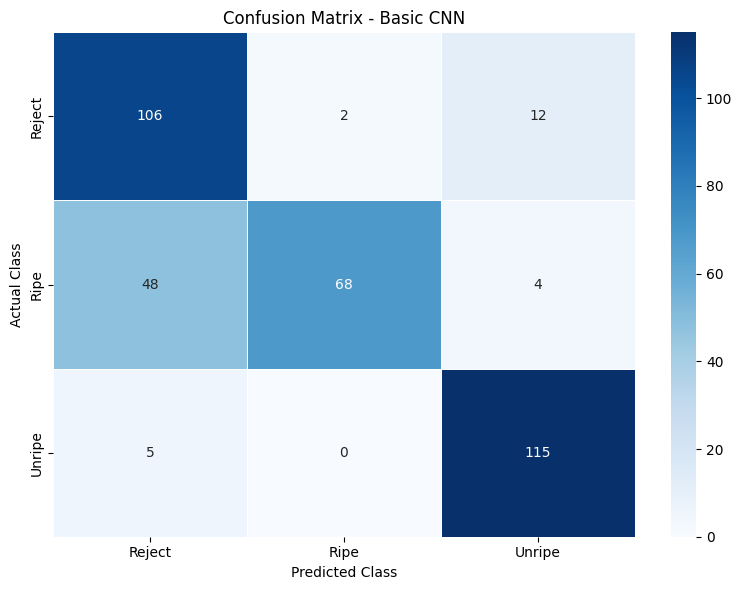

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5
)

plt.title("Confusion Matrix - Basic CNN")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [25]:
from sklearn.metrics import classification_report

print("===== Classification Report =====")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))


===== Classification Report =====
              precision    recall  f1-score   support

      Reject     0.6667    0.8833    0.7599       120
        Ripe     0.9714    0.5667    0.7158       120
      Unripe     0.8779    0.9583    0.9163       120

    accuracy                         0.8028       360
   macro avg     0.8387    0.8028    0.7973       360
weighted avg     0.8387    0.8028    0.7973       360



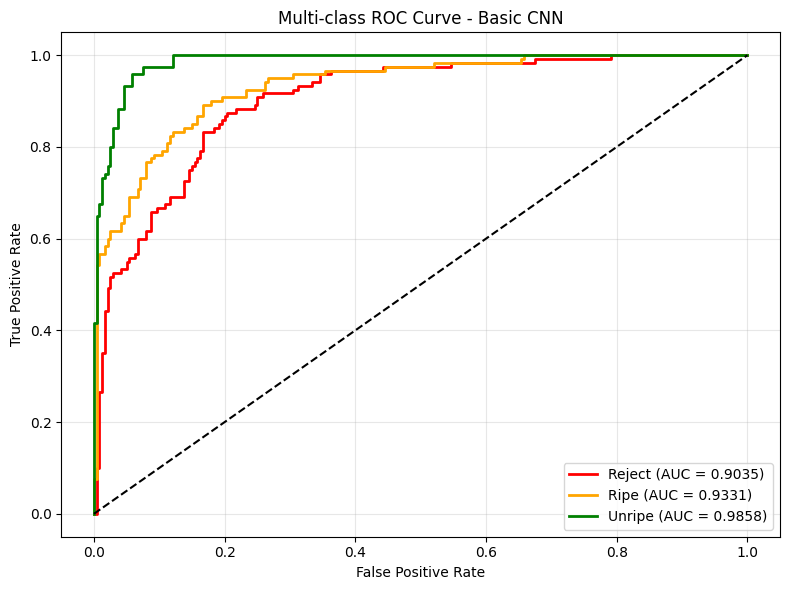

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_true_binary = label_binarize(
    y_true,
    classes=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

colors = ["red", "orange", "green"]

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(
        y_true_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        color=colors[i],
        linewidth=2,
        label=f"{class_name} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curve - Basic CNN")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



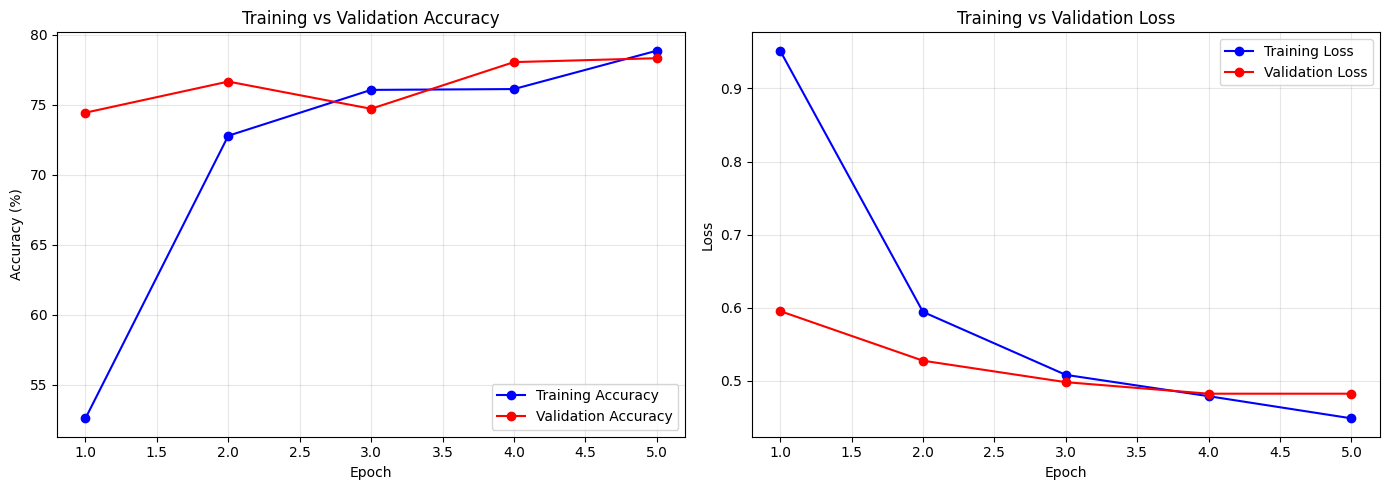

In [27]:
import matplotlib.pyplot as plt

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(epochs, train_accs, "bo-", label="Training Accuracy")
plt.plot(epochs, val_accs, "ro-", label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)

# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(epochs, train_losses, "bo-", label="Training Loss")
plt.plot(epochs, val_losses, "ro-", label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [28]:
import torch
import os

save_dir = "/content/drive/MyDrive/Tomato_CVPR"

os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "Tomato_BasicCNN.pth")

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMG_SIZE,
    "num_classes": num_classes
}, model_path)

print("Model Saved Successfully!")
print("Saved Location:", model_path)
print("File Size:", round(os.path.getsize(model_path)/(1024*1024), 2), "MB")


Model Saved Successfully!
Saved Location: /content/drive/MyDrive/Tomato_CVPR/Tomato_BasicCNN.pth
File Size: 8.1 MB


Saving Tomato250.jpg to Tomato250.jpg


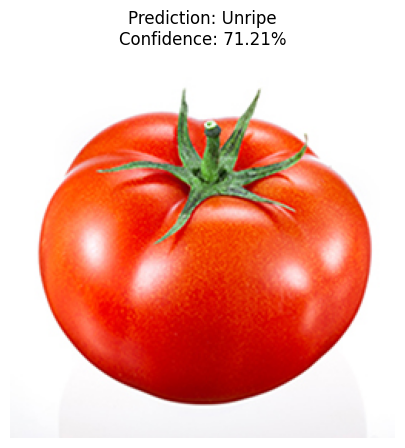

Predicted Class: Unripe
Confidence: 71.21%

Class Probabilities:
Reject: 28.46%
Ripe: 0.32%
Unripe: 71.21%


In [29]:
from google.colab import files
from PIL import Image
import torch
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

input_tensor = test_transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    confidence, predicted = torch.max(probabilities, 1)

predicted_class = class_names[predicted.item()]
confidence_score = confidence.item() * 100

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence_score:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence_score:.2f}%")

print("\nClass Probabilities:")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[0][i].item()*100:.2f}%")


Saving Media (1).jpg to Media (1).jpg


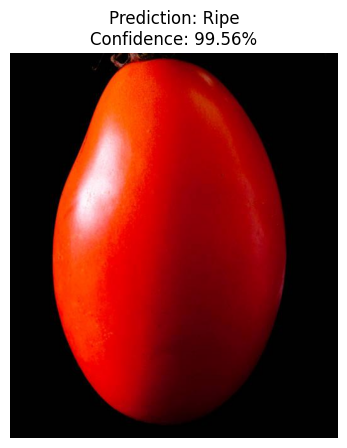

Predicted Class: Ripe
Confidence: 99.56%

Class Probabilities:
Reject: 0.44%
Ripe: 99.56%
Unripe: 0.00%


In [30]:
from google.colab import files
from PIL import Image
import torch
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))
image = Image.open(image_path).convert("RGB")

input_tensor = test_transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    confidence, predicted = torch.max(probabilities, 1)

predicted_class = class_names[predicted.item()]
confidence_score = confidence.item() * 100

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence_score:.2f}%"
)
plt.axis("off")
plt.show()

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence_score:.2f}%")

print("\nClass Probabilities:")

for i, name in enumerate(class_names):
    print(f"{name}: {probabilities[0][i].item()*100:.2f}%")
